# 04 Spatial Price Analysis

**Objective:** calculate neighbourhood-level (2020 NTA) median rental rates for each complete year (2022-2025), decide a minimum-listings rule from the actual counts, and map the results.

**Aggregation (two steps):**
1. For each listing and year, the median of its monthly `avg_daily_rate`.
2. For each NTA and year, the median of those listing-level values.

Each listing therefore contributes one value to its neighbourhood's annual median. Only rows flagged `use_in_spatial` (residential NTAs with valid coordinates) are used.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = PROJECT_ROOT / "data" / "raw"
PROCESSED = PROJECT_ROOT / "data" / "processed"
FIG = PROJECT_ROOT / "outputs" / "figures"
TAB = PROJECT_ROOT / "outputs" / "tables"
MAPS = PROJECT_ROOT / "maps"
for p in (FIG, TAB, MAPS, PROCESSED):
    p.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(PROCESSED / "past_rates_clean.parquet")
nta = gpd.read_file(RAW / "nta2020.geojson")[["nta2020", "ntaname", "boroname", "ntatype", "geometry"]]

YEARS = [2022, 2023, 2024, 2025]          # complete years only
sp = df[df["use_in_spatial"] & df["year"].isin(YEARS)].copy()
print("Rows used:", len(sp), "| listings:", sp["listing_id"].nunique())
print(sp.groupby("year")["month"].nunique().to_dict(), "<- months per year (should all be 12)")

Rows used: 120548 | listings: 4221
{2022: 12, 2023: 12, 2024: 12, 2025: 12} <- months per year (should all be 12)


In [2]:
listing_year = (sp.groupby(["nta2020", "listing_id", "year"])
                  .agg(listing_median=("avg_daily_rate", "median"),
                       months=("month", "nunique"))
                  .reset_index())

print("Listing-year values:", len(listing_year))
print()
print("Months of data behind each listing-year value (summary):")
print(listing_year["months"].describe().round(1).to_string())
print()
print("Listing-years with only 1-2 months of data:", int((listing_year["months"] <= 2).sum()),
      f"({100*(listing_year['months'] <= 2).mean():.1f}%)")

Listing-year values: 12264

Months of data behind each listing-year value (summary):
count    12264.0
mean         9.8
std          3.1
min          2.0
25%          7.0
50%         12.0
75%         12.0
max         12.0

Listing-years with only 1-2 months of data: 94 (0.8%)


In [3]:
nta_year = (listing_year.groupby(["nta2020", "year"])
                        .agg(median_rate=("listing_median", "median"),
                             n_listings=("listing_id", "nunique"))
                        .reset_index())

counts = nta_year.pivot(index="nta2020", columns="year", values="n_listings").reindex(columns=YEARS)

rows = []
for k in [1, 3, 5, 8, 10]:
    rows.append({"min_listings": k, **{str(y): int((counts[y] >= k).sum()) for y in YEARS}})
print("Number of NTAs meeting each minimum-listings threshold (out of 197 residential NTAs):")
print(pd.DataFrame(rows).to_string(index=False))
print()
print("NTAs with any data per year:", {y: int(counts[y].notna().sum()) for y in YEARS})

Number of NTAs meeting each minimum-listings threshold (out of 197 residential NTAs):
 min_listings  2022  2023  2024  2025
            1   188   184   188   170
            3   149   146   152   130
            5   129   123   125    98
            8    97    95   100    73
           10    87    87    93    65

NTAs with any data per year: {2022: 188, 2023: 184, 2024: 188, 2025: 170}


## 1. Minimum-listings rule
A neighbourhood-year is eligible for spatial analysis only if it has at least 5 listings with data that year. The threshold is a judgement call chosen from the actual counts (see table above); thresholds of 3 and 10 are used later as sensitivity checks.

In [4]:
MIN_LISTINGS = 5
nta_year = nta_year.merge(nta[["nta2020", "ntaname", "boroname"]], on="nta2020", how="left")
nta_year["eligible"] = nta_year["n_listings"] >= MIN_LISTINGS
elig = nta_year[nta_year["eligible"]].copy()

print(f"Eligible NTAs per year (min {MIN_LISTINGS} listings):", elig.groupby("year").size().to_dict())
print()
print("By borough:")
print(elig.pivot_table(index="boroname", columns="year", values="nta2020", aggfunc="count", fill_value=0).to_string())
print()
years_per_nta = elig.groupby("nta2020")["year"].nunique()
print("NTAs eligible in all 4 years:", int((years_per_nta == 4).sum()))
print("NTAs eligible in exactly 3 / 2 / 1 years:", {k: int((years_per_nta == k).sum()) for k in (3, 2, 1)})

Eligible NTAs per year (min 5 listings): {2022: 129, 2023: 123, 2024: 125, 2025: 98}

By borough:
year           2022  2023  2024  2025
boroname                             
Bronx            15    11    12     3
Brooklyn         42    40    39    34
Manhattan        31    31    31    30
Queens           37    37    39    30
Staten Island     4     4     4     1

NTAs eligible in all 4 years: 96
NTAs eligible in exactly 3 / 2 / 1 years: {3: 23, 2: 7, 1: 8}


Class breaks (USD per night): [np.float64(100.2), np.float64(156.0), np.float64(373.5)]


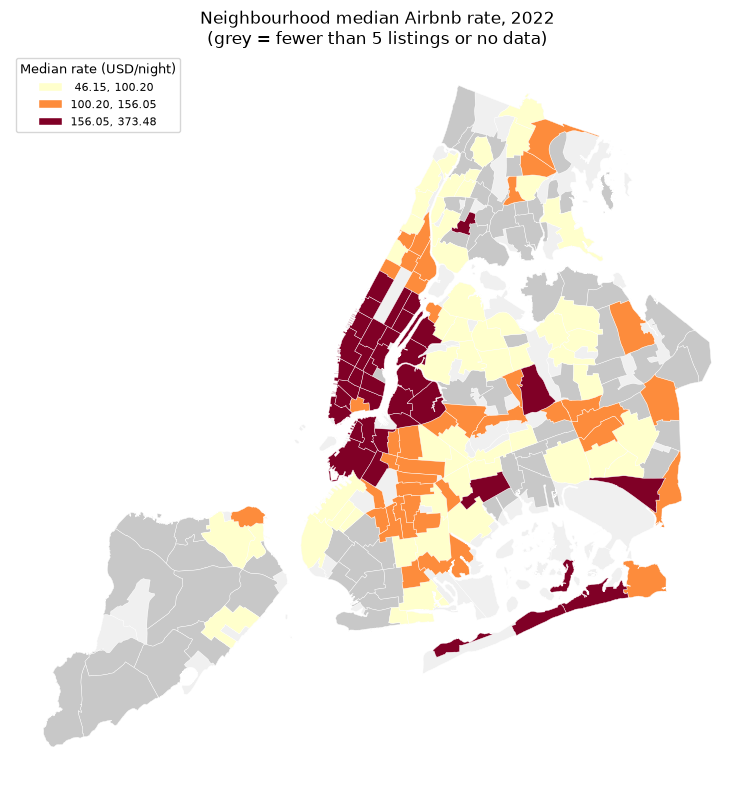

In [5]:
import mapclassify as mc

nta_res = nta[nta["ntatype"] == "0"]
bins = list(mc.Quantiles(elig["median_rate"], k=3).bins)   # tertiles of pooled 2022-2025 values
print("Class breaks (USD per night):", [round(b, 1) for b in bins])

def draw_year(year, ax):
    d = nta_res.merge(elig[elig["year"] == year][["nta2020", "median_rate"]], on="nta2020", how="left")
    nta.to_crs(2263).plot(ax=ax, color="#f0f0f0", edgecolor="white", linewidth=0.3)          # all polygons for context
    d[d["median_rate"].isna()].to_crs(2263).plot(ax=ax, color="#c8c8c8", edgecolor="white", linewidth=0.3)   # not eligible
    d[d["median_rate"].notna()].to_crs(2263).plot(column="median_rate", scheme="User_Defined",
        classification_kwds={"bins": bins}, cmap="YlOrRd", edgecolor="white", linewidth=0.3, ax=ax,
        legend=True, legend_kwds={"title": "Median rate (USD/night)", "loc": "upper left", "fontsize": 8, "title_fontsize": 9})
    ax.set_title(f"Neighbourhood median Airbnb rate, {year}\n(grey = fewer than {MIN_LISTINGS} listings or no data)")
    ax.set_axis_off()

fig, ax = plt.subplots(figsize=(8, 8))
draw_year(2022, ax)
plt.tight_layout()
plt.savefig(MAPS / "04_median_rate_2022.png", dpi=150, bbox_inches="tight")
plt.show()

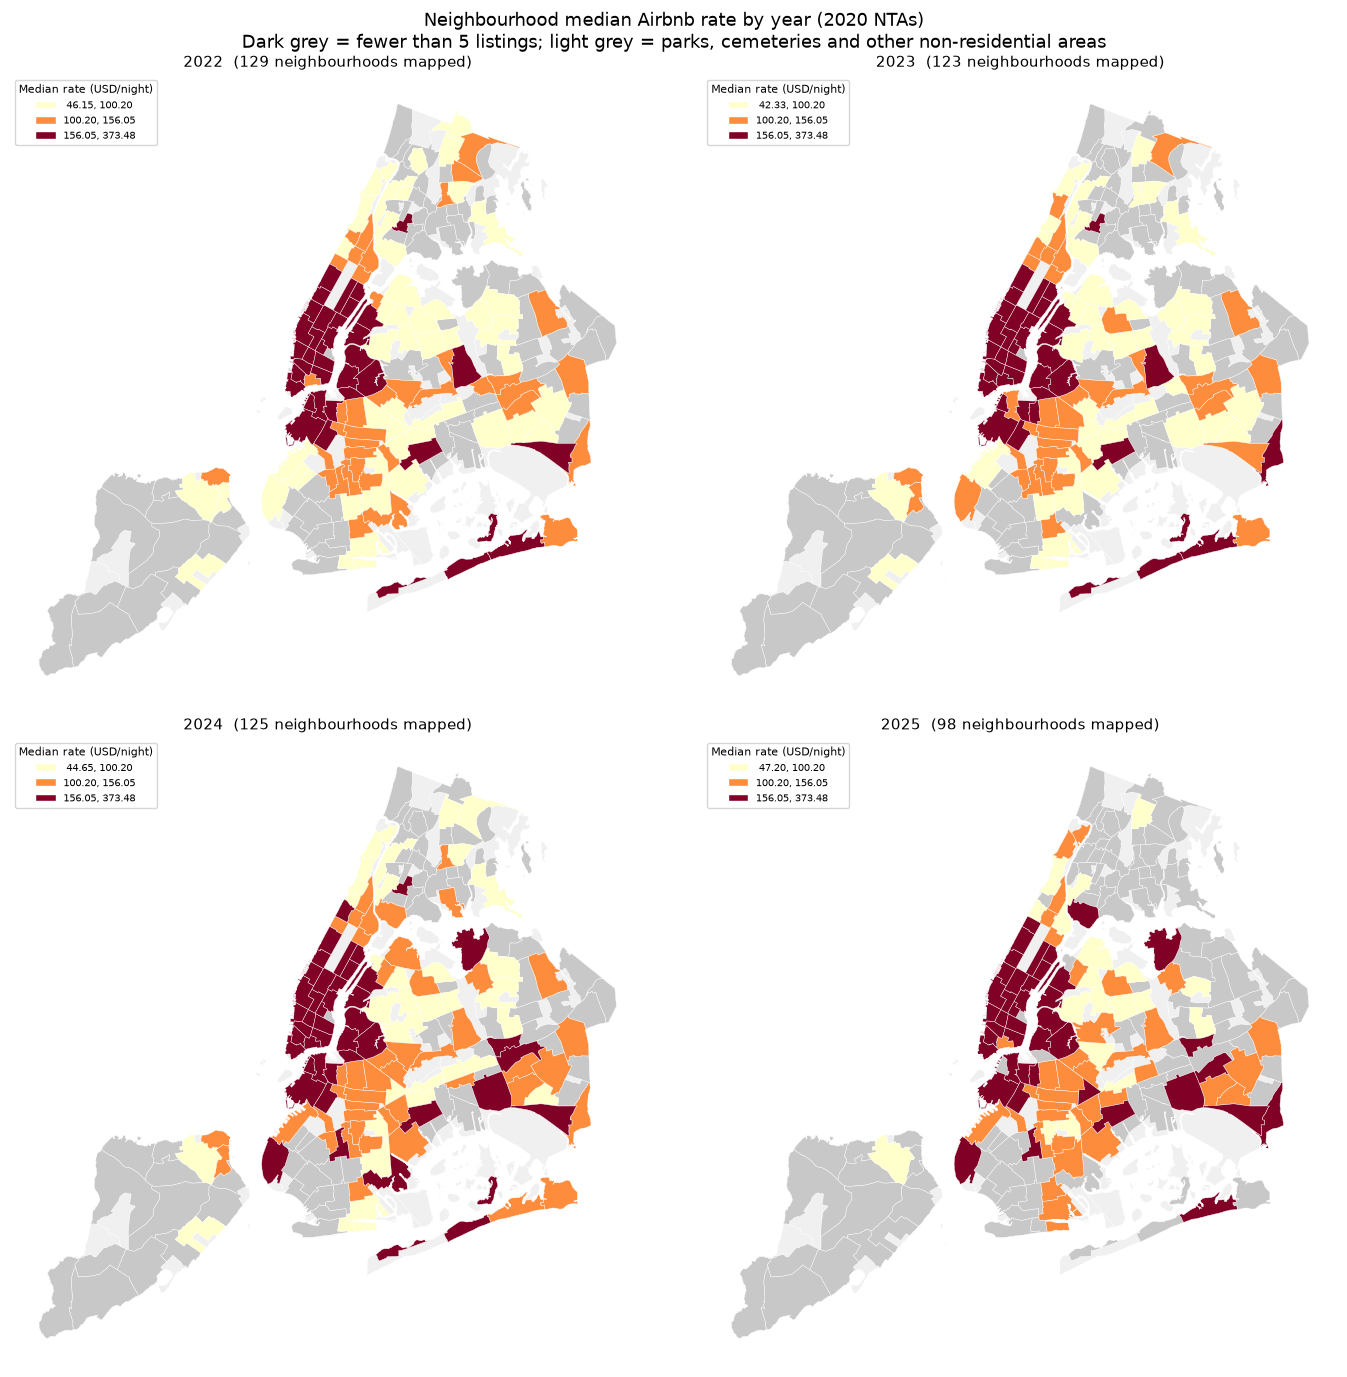

In [6]:
def draw_year(year, ax, show_legend=True):
    d = nta_res.merge(elig[elig["year"] == year][["nta2020", "median_rate"]], on="nta2020", how="left")
    nta.to_crs(2263).plot(ax=ax, color="#f0f0f0", edgecolor="white", linewidth=0.3)
    d[d["median_rate"].isna()].to_crs(2263).plot(ax=ax, color="#c8c8c8", edgecolor="white", linewidth=0.3)
    d[d["median_rate"].notna()].to_crs(2263).plot(column="median_rate", scheme="User_Defined",
        classification_kwds={"bins": bins}, cmap="YlOrRd", edgecolor="white", linewidth=0.3, ax=ax,
        legend=show_legend, legend_kwds={"title": "Median rate (USD/night)", "loc": "upper left", "fontsize": 7, "title_fontsize": 8})
    ax.set_title(f"{year}  ({int(d['median_rate'].notna().sum())} neighbourhoods mapped)", fontsize=11)
    ax.set_axis_off()

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for y, ax in zip(YEARS, axes.ravel()):
    draw_year(y, ax)
fig.suptitle(f"Neighbourhood median Airbnb rate by year (2020 NTAs)\nDark grey = fewer than {MIN_LISTINGS} listings; light grey = parks, cemeteries and other non-residential areas",
             fontsize=13)
plt.tight_layout()
plt.savefig(MAPS / "04_median_rate_2022_2025.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
for y in (2022, 2025):
    d = elig[elig["year"] == y].sort_values("median_rate")
    print(f"=== {y}: 8 lowest ===")
    print(d.head(8)[["ntaname", "boroname", "median_rate", "n_listings"]].round(1).to_string(index=False))
    print(f"=== {y}: 8 highest ===")
    print(d.tail(8).iloc[::-1][["ntaname", "boroname", "median_rate", "n_listings"]].round(1).to_string(index=False))
    print()

nta_year.to_parquet(PROCESSED / "nta_year_medians.parquet", index=False)   # local file for notebooks 06 and 07
print("Saved nta_year_medians.parquet:", nta_year.shape)

=== 2022: 8 lowest ===
                       ntaname boroname  median_rate  n_listings
               Fordham Heights    Bronx         46.2           6
                      Elmhurst   Queens         48.2          21
Pomonok-Electchester-Hillcrest   Queens         56.9           7
                   Morris Park    Bronx         57.7           5
                     Sunnyside   Queens         60.3          30
                  Bedford Park    Bronx         60.6           6
                      Woodside   Queens         61.6          26
     Throgs Neck-Schuylerville    Bronx         61.8           9
=== 2022: 8 highest ===
                             ntaname  boroname  median_rate  n_listings
                Tribeca-Civic Center Manhattan        306.6          14
             East Midtown-Turtle Bay Manhattan        284.2          37
                Midtown-Times Square Manhattan        274.6          72
                        West Village Manhattan        268.3          40
Financia

In [8]:
d = elig[elig["year"] == 2025].sort_values("median_rate")
cols = ["ntaname", "boroname", "median_rate", "n_listings"]
print("2025: 8 lowest");  print(d.head(8)[cols].round(1).to_string(index=False))
print("\n2025: 8 highest"); print(d.tail(8).iloc[::-1][cols].round(1).to_string(index=False))

2025: 8 lowest
                        ntaname  boroname  median_rate  n_listings
                       Elmhurst    Queens         47.2          11
       Williamsbridge-Olinville     Bronx         55.6           6
                  Cypress Hills  Brooklyn         60.4          15
                       Woodside    Queens         62.4          19
Astoria (East)-Woodside (North)    Queens         75.9           9
            East Flatbush-Rugby  Brooklyn         78.5          13
                      Sunnyside    Queens         79.1          19
            Morningside Heights Manhattan         82.6           5

2025: 8 highest
                             ntaname  boroname  median_rate  n_listings
                Midtown-Times Square Manhattan        373.5          64
Financial District-Battery Park City Manhattan        358.3          26
 Midtown South-Flatiron-Union Square Manhattan        331.6          49
     SoHo-Little Italy-Hudson Square Manhattan        304.5          35
     

## 2. Neighbourhood price change, 2022 to 2025
Percentage change = ((Rate_2025 - Rate_2022) / Rate_2022) × 100, using the neighbourhood median rates. Only NTAs eligible (at least 5 listings) in both years are included. Changes are described, not explained: composition of listings differs between years, so a change in a median may reflect which listings are present as well as price movement.

In [11]:
a = elig[elig["year"] == 2022].set_index("nta2020")[["ntaname", "boroname", "median_rate", "n_listings"]]
b = elig[elig["year"] == 2025].set_index("nta2020")[["median_rate", "n_listings"]]
a2 = a.rename(columns={"median_rate": "median_rate_2022", "n_listings": "n_listings_2022"})
b2 = b.rename(columns={"median_rate": "median_rate_2025", "n_listings": "n_listings_2025"})
chg = a2.join(b2, how="inner")

print("Eligible in 2022:", len(a), "| in 2025:", len(b), "| in both:", len(chg))
print("Zero or missing 2022 rates among them:", int((chg["median_rate_2022"].fillna(0) == 0).sum()))

chg = chg[chg["median_rate_2022"] > 0].copy()
chg["pct_change"] = 100 * (chg["median_rate_2025"] - chg["median_rate_2022"]) / chg["median_rate_2022"]

print()
print("Percentage change across NTAs (summary):")
print(chg["pct_change"].describe().round(1).to_string())
print()
print("NTAs with a rise / fall:", int((chg["pct_change"] > 0).sum()), "/", int((chg["pct_change"] < 0).sum()))
print("Within +/-10%:", int(chg["pct_change"].between(-10, 10).sum()))

cols = ["ntaname", "boroname", "median_rate_2022", "median_rate_2025", "pct_change", "n_listings_2022", "n_listings_2025"]
print("\n10 largest increases"); print(chg.nlargest(10, "pct_change")[cols].round(1).to_string(index=False))
print("\n10 largest decreases"); print(chg.nsmallest(10, "pct_change")[cols].round(1).to_string(index=False))

chg.reset_index().to_csv(TAB / "04_pct_change_2022_2025.csv", index=False)

Eligible in 2022: 129 | in 2025: 98 | in both: 96
Zero or missing 2022 rates among them: 0

Percentage change across NTAs (summary):
count     96.0
mean      21.9
std       34.1
min      -30.2
25%        1.5
50%       17.7
75%       31.7
max      193.2

NTAs with a rise / fall: 77 / 19
Within +/-10%: 32

10 largest increases
                                     ntaname  boroname  median_rate_2022  median_rate_2025  pct_change  n_listings_2022  n_listings_2025
                      Mott Haven-Port Morris     Bronx              76.7             224.8       193.2               14                7
                            South Ozone Park    Queens              98.2             243.0       147.5                9                7
                                  Ocean Hill  Brooklyn              79.6             171.8       115.7               40               22
            Upper West Side-Manhattan Valley Manhattan             104.2             193.2        85.3               49      

In [12]:
print("10 largest decreases")
print(chg.nsmallest(10, "pct_change")[cols].round(1).to_string(index=False))

10 largest decreases
                 ntaname  boroname  median_rate_2022  median_rate_2025  pct_change  n_listings_2022  n_listings_2025
            Forest Hills    Queens             162.1             113.2       -30.2               16               10
           Cypress Hills  Brooklyn              80.5              60.4       -25.0               24               15
     East Harlem (North) Manhattan             126.0              98.2       -22.1               48               26
Williamsbridge-Olinville     Bronx              68.4              55.6       -18.8               10                6
   East Flatbush-Erasmus  Brooklyn             119.2              99.5       -16.6               19               13
                Gramercy Manhattan             223.8             194.6       -13.1               33               24
               Ridgewood    Queens             107.2              93.4       -12.9               31               18
            West Village Manhattan         

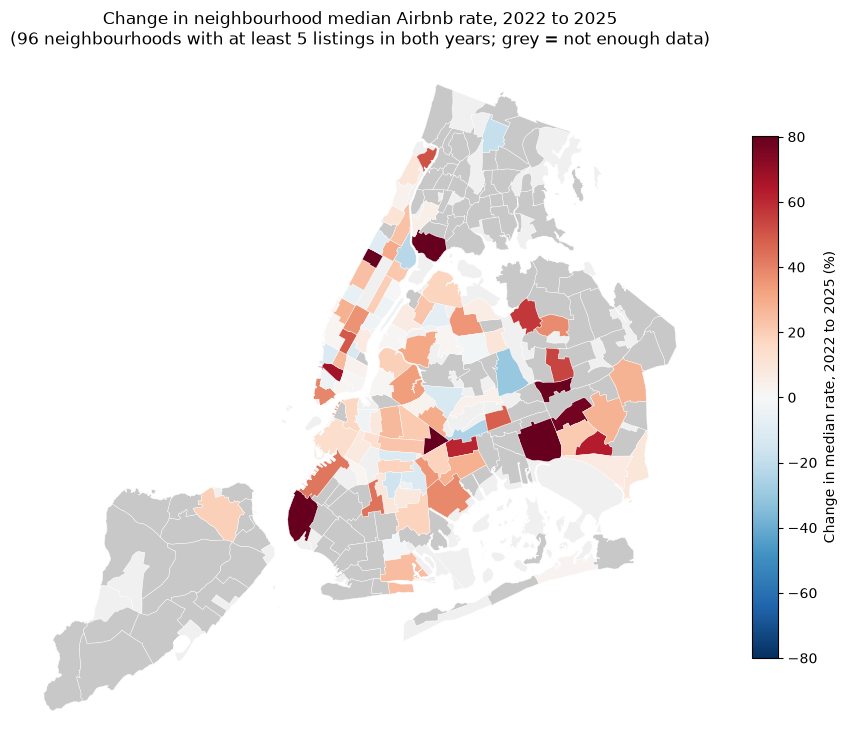

In [10]:
from matplotlib.colors import TwoSlopeNorm

lim = float(max(abs(chg["pct_change"].quantile(0.05)), abs(chg["pct_change"].quantile(0.95))))
norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)

d = nta_res.merge(chg.reset_index()[["nta2020", "pct_change"]], on="nta2020", how="left")
fig, ax = plt.subplots(figsize=(9, 9))
nta.to_crs(2263).plot(ax=ax, color="#f0f0f0", edgecolor="white", linewidth=0.3)
d[d["pct_change"].isna()].to_crs(2263).plot(ax=ax, color="#c8c8c8", edgecolor="white", linewidth=0.3)
d[d["pct_change"].notna()].to_crs(2263).plot(column="pct_change", cmap="RdBu_r", norm=norm, edgecolor="white",
        linewidth=0.3, ax=ax, legend=True, legend_kwds={"label": "Change in median rate, 2022 to 2025 (%)", "shrink": 0.6})
ax.set_title(f"Change in neighbourhood median Airbnb rate, 2022 to 2025\n({len(chg)} neighbourhoods with at least {MIN_LISTINGS} listings in both years; grey = not enough data)")
ax.set_axis_off()
plt.tight_layout()
plt.savefig(MAPS / "04_pct_change_2022_2025.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary
- Neighbourhood medians use a two-step method: the median of each listing's monthly rates per year, then the median of those values within each 2020 NTA. Only residential NTAs with valid coordinates (`use_in_spatial`) and the complete years 2022-2025 are used.
- Minimum-listings rule: at least 5 listings per NTA per year. Eligible NTAs: 129 (2022), 123 (2023), 125 (2024), 98 (2025). 96 NTAs are eligible in all four years. The Bronx drops from 15 eligible NTAs (2022) to 3 (2025) and Staten Island from 4 to 1.
- Class breaks (fixed across years, tertiles of pooled values): $100.20 and $156.05. In 2022 the eight highest NTAs were all in Manhattan ($224 to $307) and the eight lowest in the Bronx and Queens ($46 to $62). In 2025 the eight highest were again all in Manhattan ($255 to $374).
- Change 2022 to 2025 (96 NTAs eligible in both years): median +17.7%, mean +21.9%, interquartile range +1.5% to +31.7%, range -30.2% to +193.2%. 77 NTAs rose, 19 fell, 32 changed by less than 10%.
- Largest increases: Mott Haven-Port Morris (+193.2%), South Ozone Park (+147.5%), Ocean Hill (+115.7%). Largest decreases: Forest Hills (-30.2%), Cypress Hills (-25.0%), East Harlem (North) (-22.1%).

## Limitations / observations
- Some NTAs rest on few listings (5 to 14), including several with the largest changes; the minimum of 5 is a judgement, not a guarantee of reliability.
- The set of NTAs with enough listings differs by year, and the set of listings differs by year, so changes may partly reflect composition.
- Rates are nominal USD and not inflation-adjusted.
- Grey areas on the maps mean insufficient data, not low prices.
- Planned sensitivity checks: thresholds of 3 and 10 listings, months with occupancy above 0 only, entire homes only, and listings present in both 2022 and 2025.

**Note added after the sensitivity checks (notebook 08):** with only listings present in both 2022 and 2025 the median neighbourhood change was +2.6% (79 NTAs) and the direction agreed with the figures above in 48 of 79 NTAs, so the neighbourhood-level changes in this notebook should be read as differences between medians of changing samples, not as price movements.